# YOLOv10-S + P2 head on UA-DETRAC

Compares the P2 detector with the fine-tuned YOLOv10-S baseline. Set SMOKE_TEST to True for a quick test.

## 1. CONFIG

In [64]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/DATA255
!ls

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/.shortcut-targets-by-id/1bo0ITDfSqcaoFTjJXtJVrUDLpPS9E0SS/DATA255
annotations.csv  outputs  processed.zip  yolov10s-p2.yaml  yolov10s.pt


In [65]:
import sys, io, json, time, random, shutil, contextlib, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import torch
from PIL import Image
import matplotlib.pyplot as plt

IN_COLAB = 'google.colab' in sys.modules

# set root directory to the parent of notebooks/ if we are in notebooks/, otherwise cwd
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

SMOKE_TEST = False   # True = quick test, False = real run

if IN_COLAB:
    COLAB_ZIP = Path('/content/drive/MyDrive/DATA255/processed.zip')     # zip of traffic-monitoring/data/processed
    DATA_DIR = Path('/content/processed')                               # where the zip is extracted
    OUTPUT_DIR = Path('/content/drive/MyDrive/DATA255/outputs/yolov10_p2')
    BASELINE_DIR = Path('/content/drive/MyDrive/DATA255/outputs/yolov10_baseline')   # Person 2's results
else:
    DATA_DIR = ROOT / 'traffic-monitoring' / 'data' / 'processed'
    OUTPUT_DIR = ROOT / 'outputs' / 'yolov10_p2'
    BASELINE_DIR = ROOT / 'outputs' / 'yolov10_baseline'

# The ONLY change from the baseline: the architecture. P2 yaml is looked for in the repo, then on Drive.
P2_YAML_CANDIDATES = [ROOT / 'models' / 'yolov10s-p2.yaml', ROOT.parent / 'models' / 'yolov10s-p2.yaml',
                      Path('/content/drive/MyDrive/DATA255/yolov10s-p2.yaml')]
MODEL = str(next((p for p in P2_YAML_CANDIDATES if p.exists()), P2_YAML_CANDIDATES[0]))
PRETRAINED = 'yolov10s.pt'   # same starting weights as the baseline; loaded where layer names and shapes match
EPOCHS = 50
PATIENCE = 10
IMGSZ = 640
BATCH = 16
SEED = 0
FRACTION = 1.0

EVAL_CONF = 0.001
COUNT_CONF = 0.25
IOU_MATCH = 0.5
SMOKE_TEST_IMAGES_PER_WEATHER = 10

BASELINE_PT = BASELINE_DIR / 'finetune' / 'weights' / 'best.pt'   # never retrained here

if SMOKE_TEST:
    EPOCHS = 2
    FRACTION = 0.1
    OUTPUT_DIR = OUTPUT_DIR / 'smoke_test'

if torch.cuda.is_available():
    DEVICE = 0
elif torch.backends.mps.is_available():
    DEVICE = 'mps'
else:
    DEVICE = 'cpu'

# mapped COCO class IDs to our class IDs (0=car, 1=bus, 2=others)
COCO_TO_OURS = {2: 0,   # car   -> car
                5: 1,   # bus   -> bus
                7: 3}   # truck -> others

random.seed(SEED)
np.random.seed(SEED)
if not IN_COLAB:   # on Colab the folder is on Drive, so it is created after Drive is mounted (SETUP)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f'SMOKE_TEST={SMOKE_TEST}  DEVICE={DEVICE}  EPOCHS={EPOCHS}  FRACTION={FRACTION}')
print('DATA_DIR  :', DATA_DIR)
print('OUTPUT_DIR:', OUTPUT_DIR)
print('MODEL     :', MODEL, '| exists:', Path(MODEL).exists())
print('BASELINE  :', BASELINE_PT, '| exists:', BASELINE_PT.exists())

SMOKE_TEST=False  DEVICE=0  EPOCHS=50  FRACTION=1.0
DATA_DIR  : /content/processed
OUTPUT_DIR: /content/drive/MyDrive/DATA255/outputs/yolov10_p2
MODEL     : /content/drive/MyDrive/DATA255/yolov10s-p2.yaml | exists: True
BASELINE  : /content/drive/MyDrive/DATA255/outputs/yolov10_baseline/finetune/weights/best.pt | exists: True


## 2. SETUP

For Colab: mount Google Drive and copy the P2 model and processed dataset files, skipped if local

In [66]:
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics', 'pycocotools'], check=True)
    if not DATA_DIR.exists():
        shutil.unpack_archive(COLAB_ZIP, DATA_DIR.parent)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    MODEL = str(next((p for p in P2_YAML_CANDIDATES if p.exists()), P2_YAML_CANDIDATES[0]))   # Drive is mounted now
else:
    print('Not on Colab: skipping')

assert Path(MODEL).exists(), f'P2 yaml not found in {P2_YAML_CANDIDATES}: copy models/yolov10s-p2.yaml to MyDrive/DATA255/'
assert BASELINE_PT.exists(), f'Baseline weights not found at {BASELINE_PT} (Person 2 Drive folder)'


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Load the dataset information and create the image lists and data.yaml copies used below.

In [67]:
from ultralytics import YOLO
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

# Read the original data.yaml (class names + split folders)
with open(DATA_DIR / 'data.yaml') as f:
    original_yaml = yaml.safe_load(f)
names = original_yaml['names']
CLASS_NAMES = list(names) if isinstance(names, list) else [names[i] for i in sorted(names)]
NUM_CLASSES = len(CLASS_NAMES)
SPLITS = ['train', 'val', 'test']

# Dataset view: OUTPUT_DIR/dataset_view/{images,labels}/{split} are symlinks to the real folders
# On Colab keep the symlink view on the local disk: links stored on Drive make every image read go through Drive
VIEW_DIR = Path('/content/dataset_view') if IN_COLAB else OUTPUT_DIR / 'dataset_view'
for split in SPLITS:
    image_dir = DATA_DIR / original_yaml[split]
    label_dir = DATA_DIR / original_yaml[split].replace('images', 'labels', 1)
    for kind, target in [('images', image_dir), ('labels', label_dir)]:
        link = VIEW_DIR / kind / split
        link.parent.mkdir(parents=True, exist_ok=True)
        if link.is_symlink() or link.exists():
            link.unlink()
        link.symlink_to(target.resolve(), target_is_directory=True)

manifest = pd.read_csv(DATA_DIR / 'frame_manifest.csv')
manifest['image'] = manifest['image_path'].map(lambda p: Path(p).stem)
manifest['image_file'] = [str(VIEW_DIR / 'images' / s / Path(p).name) for s, p in zip(manifest['split'], manifest['image_path'])]
manifest['label_file'] = [str(VIEW_DIR / 'labels' / s / f'{i}.txt') for s, i in zip(manifest['split'], manifest['image'])]
missing = [p for p in manifest['image_file'] if not Path(p).exists()]
assert not missing, f'{len(missing)} manifest images not found, e.g. {missing[:3]}'


test_df = manifest[manifest['split'] == 'test']
if SMOKE_TEST:
    n = min(SMOKE_TEST_IMAGES_PER_WEATHER, test_df['weather'].value_counts().min())
    test_df = test_df.groupby('weather').sample(n=n, random_state=SEED)
test_df = test_df.reset_index(drop=True)
WEATHERS = sorted(test_df['weather'].unique())

LIST_DIR = OUTPUT_DIR / 'image_lists'
LIST_DIR.mkdir(exist_ok=True)

def write_list(images, name):
    list_file = LIST_DIR / f'{name}.txt'
    list_file.write_text('\n'.join(images) + '\n')
    return str(list_file)

TRAIN_LIST = write_list(manifest.loc[manifest['split'] == 'train', 'image_file'], 'train')
VAL_LIST = write_list(manifest.loc[manifest['split'] == 'val', 'image_file'], 'val')

def make_yaml(test_images, name):
    yaml_file = OUTPUT_DIR / f'{name}.yaml'
    with open(yaml_file, 'w') as f:
        yaml.safe_dump({'path': str(VIEW_DIR), 'train': TRAIN_LIST, 'val': VAL_LIST,
                        'test': write_list(test_images, name), 'names': CLASS_NAMES}, f, sort_keys=False)
    return str(yaml_file)

RUNTIME_YAML = make_yaml(test_df['image_file'].tolist(), 'data_runtime')
WEATHER_YAMLS = {w: make_yaml(g['image_file'].tolist(), f'data_test_{w}') for w, g in test_df.groupby('weather')}

print('Classes:', CLASS_NAMES)
print('Runtime yaml:', RUNTIME_YAML)
display(pd.crosstab(manifest['weather'], manifest['split'], margins=True))
print(f'Evaluating on {len(test_df)} test images:', test_df['weather'].value_counts().to_dict())

Classes: ['car', 'bus', 'van', 'others']
Runtime yaml: /content/drive/MyDrive/DATA255/outputs/yolov10_p2/data_runtime.yaml


split,test,train,val,All
weather,,,,
cloudy,402,3468,649,4519
night,521,3407,657,4585
rainy,800,2583,637,4020
sunny,766,2342,595,3703
All,2489,11800,2538,16827


Evaluating on 2489 test images: {'rainy': 800, 'sunny': 766, 'night': 521, 'cloudy': 402}


Use the shared scoring helpers from the baseline.

In [68]:
BOX_COLS = ['x1', 'y1', 'x2', 'y2']


def load_ground_truth(images_df):
    # Reads the YOLO label files and return one row per box in pixel coordinates.
    rows = []
    for r in images_df.itertuples():
        width, height = Image.open(r.image_file).size
        for line in Path(r.label_file).read_text().splitlines():
            if not line.strip():
                continue
            class_id, xc, yc, w, h = line.split()
            xc, w = float(xc) * width, float(w) * width
            yc, h = float(yc) * height, float(h) * height
            rows.append({'image': r.image, 'class_id': int(class_id),
                         'x1': xc - w / 2, 'y1': yc - h / 2, 'x2': xc + w / 2, 'y2': yc + h / 2})
    return pd.DataFrame(rows, columns=['image', 'class_id'] + BOX_COLS)


def predict_detections(model, images_df, conf, class_map=None):
    # Predicts boxes for the given images and returns one row per box in pixel coordinates.
    rows = []
    paths = images_df['image_file'].tolist()
    for start in range(0, len(paths), BATCH):
        results = model.predict(paths[start:start + BATCH], conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False)
        for result in results:
            image = Path(result.path).stem
            boxes = result.boxes
            for box, cls, score in zip(boxes.xyxy.tolist(), boxes.cls.int().tolist(), boxes.conf.tolist()):
                if class_map is not None:
                    if cls not in class_map:
                        continue
                    cls = class_map[cls]
                rows.append({'image': image, 'class_id': cls, 'confidence': score,
                             'x1': box[0], 'y1': box[1], 'x2': box[2], 'y2': box[3]})
        del results
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return pd.DataFrame(rows, columns=['image', 'class_id', 'confidence'] + BOX_COLS)


def coco_ap(gt, det, image_names, agnostic=False):
    # AP with pycocotools. Returns {name: (AP50, AP50_95)} per class plus 'all' (mean over classes).
    # Classes with no ground truth in these images get NaN. agnostic=True -> one 'vehicle' class.
    image_ids = {name: i + 1 for i, name in enumerate(image_names)}
    gt = gt[gt['image'].isin(image_ids)]
    det = det[det['image'].isin(image_ids)]
    cat_names = ['vehicle'] if agnostic else CLASS_NAMES
    to_cat = (lambda c: 1) if agnostic else (lambda c: int(c) + 1)   # COCO category IDs start at 1

    coco_gt = COCO()
    coco_gt.dataset = {
        'images': [{'id': i} for i in image_ids.values()],
        'categories': [{'id': k + 1, 'name': n} for k, n in enumerate(cat_names)],
        'annotations': [{'id': k + 1, 'image_id': image_ids[r.image], 'category_id': to_cat(r.class_id),
                         'bbox': [r.x1, r.y1, r.x2 - r.x1, r.y2 - r.y1],
                         'area': (r.x2 - r.x1) * (r.y2 - r.y1), 'iscrowd': 0}
                        for k, r in enumerate(gt.itertuples())],
    }
    has_gt = {n: (gt['class_id'] == k).any() if not agnostic else len(gt) > 0 for k, n in enumerate(cat_names)}

    if len(det) == 0:   # no detections at all: AP is 0 wherever there is ground truth
        out = {n: (0.0, 0.0) if has_gt[n] else (np.nan, np.nan) for n in cat_names}
    else:
        with contextlib.redirect_stdout(io.StringIO()):   # hide pycocotools' printouts
            coco_gt.createIndex()
            coco_det = coco_gt.loadRes([{'image_id': image_ids[r.image], 'category_id': to_cat(r.class_id),
                                         'bbox': [r.x1, r.y1, r.x2 - r.x1, r.y2 - r.y1], 'score': r.confidence}
                                        for r in det.itertuples()])
            ev = COCOeval(coco_gt, coco_det, 'bbox')
            ev.params.maxDets = [1, 10, 300]   # allow up to 300 boxes per image (busy traffic scenes)
            ev.evaluate()
            ev.accumulate()
        # precision has shape [IoU thresholds (0.5..0.95), recall points, class, area range, maxDets]
        precision = ev.eval['precision'][:, :, :, 0, -1]
        out = {}
        for k, n in enumerate(cat_names):
            p = precision[:, :, k]
            out[n] = (p[0][p[0] > -1].mean(), p[p > -1].mean()) if has_gt[n] else (np.nan, np.nan)

    out['all'] = tuple(np.nanmean([out[n][j] for n in cat_names]) for j in (0, 1))
    return out


def box_iou(a, b):
    # IoU between every box in a (N, 4) and every box in b (M, 4), both in x1, y1, x2, y2 format.
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter)


def precision_recall(gt, det, agnostic=False):
    # Precision and recall at confidence >= COUNT_CONF and IoU >= IOU_MATCH.
    # Detections are matched greedily (highest confidence first) to unmatched GT boxes.
    # Returns {name: (precision, recall)}; precision is NaN for a class with no detections.
    det = det[det['confidence'] >= COUNT_CONF].sort_values('confidence', ascending=False).copy()
    det['tp'] = False
    key = ['image'] if agnostic else ['image', 'class_id']
    gt_by_key = dict(list(gt.groupby(key)))
    for k, d in det.groupby(key):
        g = gt_by_key.get(k)
        if g is None:
            continue
        ious = box_iou(d[BOX_COLS].to_numpy(), g[BOX_COLS].to_numpy())
        used = np.zeros(len(g), dtype=bool)
        for i, idx in enumerate(d.index):         # d keeps the confidence order
            candidates = np.where(~used & (ious[i] >= IOU_MATCH))[0]
            if len(candidates):
                used[candidates[np.argmax(ious[i, candidates])]] = True
                det.at[idx, 'tp'] = True

    def pr(d, n_gt):
        return (d['tp'].mean() if len(d) else np.nan, d['tp'].sum() / n_gt if n_gt else np.nan)

    if agnostic:
        return {'vehicle': pr(det, len(gt))}
    out = {n: pr(det[det['class_id'] == c], (gt['class_id'] == c).sum()) for c, n in enumerate(CLASS_NAMES)}
    out['all'] = pr(det, len(gt))
    return out


def evaluate(gt, det, images_df):
    # evaltuate all detection metrics for one model, as a long table: group, metric, value.
    image_names = images_df['image'].tolist()
    gt = gt[gt['image'].isin(image_names)]
    rows = []
    ap, pr = coco_ap(gt, det, image_names), precision_recall(gt, det)
    for group in ['all'] + CLASS_NAMES:
        rows += [(group, 'mAP50', ap[group][0]), (group, 'mAP50_95', ap[group][1]),
                 (group, 'precision', pr[group][0]), (group, 'recall', pr[group][1])]
    # mAP over only the classes that have a COCO equivalent (a fairer zero-shot comparison)
    mapped = [CLASS_NAMES[c] for c in sorted(set(COCO_TO_OURS.values()))]
    rows += [('coco_mapped_classes', m, np.nanmean([ap[n][j] for n in mapped])) for j, m in enumerate(['mAP50', 'mAP50_95'])]
    ap_v, pr_v = coco_ap(gt, det, image_names, agnostic=True)['vehicle'], precision_recall(gt, det, agnostic=True)['vehicle']
    rows += [('vehicle', 'mAP50', ap_v[0]), ('vehicle', 'mAP50_95', ap_v[1]),
             ('vehicle', 'precision', pr_v[0]), ('vehicle', 'recall', pr_v[1])]
    for weather, g in images_df.groupby('weather'):
        ap_w = coco_ap(gt, det, g['image'].tolist())['all']
        rows += [(f'weather:{weather}', 'mAP50', ap_w[0]), (f'weather:{weather}', 'mAP50_95', ap_w[1])]
    return pd.DataFrame(rows, columns=['group', 'metric', 'value'])


def count_table(gt, det, images_df):
    # Count the number of boxes per image, per class, and overall, for both ground truth and predictions.
    det = det[det['confidence'] >= COUNT_CONF]
    counts = images_df[['image', 'sequence', 'frame', 'weather']].copy()
    for prefix, boxes in [('gt', gt), ('pred', det)]:
        per_class = (boxes.groupby(['image', 'class_id']).size().unstack(fill_value=0)
                     .reindex(index=counts['image'], columns=range(NUM_CLASSES), fill_value=0))
        for c, n in enumerate(CLASS_NAMES):
            counts[f'{prefix}_{n}'] = per_class[c].to_numpy()
        counts[f'{prefix}_total'] = per_class.sum(axis=1).to_numpy()
    return counts


def count_mae(counts):
    # Mean absolute counting error per image: overall, per class and per weather.
    err = lambda d, n: (d[f'pred_{n}'] - d[f'gt_{n}']).abs().mean()
    rows = [('all', 'count_MAE', err(counts, 'total'))]
    rows += [(n, 'count_MAE', err(counts, n)) for n in CLASS_NAMES]
    rows += [(f'weather:{w}', 'count_MAE', err(g, 'total')) for w, g in counts.groupby('weather')]
    return pd.DataFrame(rows, columns=['group', 'metric', 'value'])


test_gt = load_ground_truth(test_df)
print(f'{len(test_gt)} ground-truth boxes in {len(test_df)} test images')

13221 ground-truth boxes in 2489 test images


## 3. P2 ARCHITECTURE CHECK (no training)

Check the P2 strides, pretrained weight transfer, and model size.

In [69]:
from ultralytics.utils.torch_utils import get_flops

p2_check = YOLO(MODEL)                                   # random init, nc from the yaml (80, like yolov10s.pt)
strides = [int(s) for s in p2_check.model.stride.tolist()]
p2_check.model.eval()
with torch.no_grad():
    p2_check.model(torch.zeros(1, 3, IMGSZ, IMGSZ))
assert strides == [4, 8, 16, 32], f'P2 head not built as intended: strides {strides}'

pretrained_ref = YOLO(PRETRAINED)
src_sd = pretrained_ref.model.state_dict()
dst_sd = YOLO(MODEL).load(PRETRAINED).model.state_dict()   # the same call used for training below
transferred = [k for k in dst_sd if k in src_sd and dst_sd[k].shape == src_sd[k].shape]
layer_of = lambda k: int(k.split('.')[1])
new_layers = sorted({layer_of(k) for k in dst_sd if k not in transferred})


def size_info(m):
    return {'params_M': sum(p.numel() for p in m.model.parameters()) / 1e6, 'GFLOPs': get_flops(m.model, IMGSZ)}


ARCH_INFO = {'strides': strides, 'transferred_tensors': len(transferred), 'total_tensors': len(dst_sd),
             'layers_starting_from_scratch': new_layers,
             'baseline_nc80': size_info(pretrained_ref), 'p2_nc80': size_info(p2_check)}
(OUTPUT_DIR / 'architecture_check.json').write_text(json.dumps(ARCH_INFO, indent=2))
print('Forward pass OK, strides', strides)
print(f'Pretrained tensors transferred: {len(transferred)}/{len(dst_sd)}')
print('Layers that start from scratch:', new_layers, '(expected [25, 26]: new C2f + detection head; layers 23-24 are upsample/concat with no weights)')
print('Baseline:', {k: round(v, 2) for k, v in ARCH_INFO['baseline_nc80'].items()},
      '| P2:', {k: round(v, 2) for k, v in ARCH_INFO['p2_nc80'].items()}, '(80-class heads; 4-class numbers in the summary)')
del p2_check, pretrained_ref

Transferred 378/723 items from pretrained weights
Forward pass OK, strides [4, 8, 16, 32]
Pretrained tensors transferred: 378/723
Layers that start from scratch: [25, 26] (expected [25, 26]: new C2f + detection head; layers 23-24 are upsample/concat with no weights)
Baseline: {'params_M': 8.13, 'GFLOPs': 25.23} | P2: {'params_M': 8.19, 'GFLOPs': 36.5} (80-class heads; 4-class numbers in the summary)


## 4. BASELINE PREDICTIONS

Run the fine tuned baseline on the test set for side by side comparison.

In [70]:
baseline_model = YOLO(BASELINE_PT)
start = time.time()
base_det = predict_detections(baseline_model, test_df, conf=EVAL_CONF)
print(f'Baseline prediction: {time.time() - start:.0f}s, {len(base_det)} boxes')

base_metrics = evaluate(test_gt, base_det, test_df)
display(base_metrics.pivot(index='group', columns='metric', values='value').round(3))

Baseline prediction: 34s, 46796 boxes


metric,mAP50,mAP50_95,precision,recall
group,,,,
all,0.631,0.469,0.883,0.807
bus,0.889,0.672,0.894,0.835
car,0.863,0.649,0.910,0.815
coco_mapped_classes,0.637,0.476,NaN,NaN
others,0.159,0.108,0.232,0.356
van,0.613,0.448,0.580,0.639
vehicle,0.879,0.657,0.906,0.828
weather:cloudy,0.746,0.496,NaN,NaN
weather:night,0.613,0.431,NaN,NaN


## 5. FINE TUNE YOLOv10-S + P2

Fine tune the P2 model and resume from its last checkpoint if interrupted.

In [71]:
RUN_DIR = OUTPUT_DIR / 'finetune'
LAST_PT = RUN_DIR / 'weights' / 'last.pt'
BEST_PT = RUN_DIR / 'weights' / 'best.pt'
DONE_FILE = RUN_DIR / 'TRAINING_DONE'

start = time.time()
if DONE_FILE.exists():
    print('Training already finished:', DONE_FILE.read_text())
elif LAST_PT.exists():
    print('Resuming from', LAST_PT)
    # data/device are passed again so a run started on the Mac can resume on Colab (and vice versa)
    YOLO(LAST_PT).train(resume=True, data=RUNTIME_YAML, device=DEVICE)
else:
    YOLO(MODEL).load(PRETRAINED).train(data=RUNTIME_YAML, epochs=EPOCHS, patience=PATIENCE, imgsz=IMGSZ, batch=BATCH,
                                       seed=SEED, deterministic=True, device=DEVICE, fraction=FRACTION,
                                       project=str(OUTPUT_DIR), name='finetune', exist_ok=True, plots=True)

if not DONE_FILE.exists():
    history = pd.read_csv(RUN_DIR / 'results.csv')
    history.columns = history.columns.str.strip()
    info = {'epochs_completed': len(history), 'session_seconds': round(time.time() - start),
            'best_epoch_by_val_mAP50_95': int(history.loc[history['metrics/mAP50-95(B)'].idxmax(), 'epoch']),
            'total_train_seconds': round(history['time'].iloc[-1]) if 'time' in history else None}
    DONE_FILE.write_text(json.dumps(info))
    print('Training finished:', info)

Transferred 378/723 items from pretrained weights
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/DATA255/outputs/yolov10_p2/data_runtime.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/DATA255/yo

## 6. FINAL EVALUATION

Evaluate the best P2 checkpoint on the test set.

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv10s-p2 summary (fused): 118 layers, 7,272,800 parameters, 0 gradients, 27.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 37.5±16.8 MB/s, size: 57.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/dataset_view/labels/test... 2489 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2489/2489 831.6it/s 3.0s
val: New cache created: /content/dataset_view/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 156/156 4.8it/s 32.3s
                   all       2489      13221       0.67      0.626      0.658      0.493
Speed: 0.6ms preprocess, 7.4ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to /content/drive/.shortcut-targets-by-id/1bo0ITDfSqcaoFTjJXtJVrUDLpPS9E0SS/DATA

,class,precision,recall,mAP50,mAP50_95
0,all,0.670,0.626,0.658,0.493
1,car,0.967,0.799,0.920,0.682
2,bus,0.970,0.840,0.925,0.681
3,van,0.691,0.709,0.719,0.550
4,others,0.053,0.156,0.067,0.057


Saved /content/drive/.shortcut-targets-by-id/1bo0ITDfSqcaoFTjJXtJVrUDLpPS9E0SS/DATA255/outputs/yolov10_p2/test_eval/confusion_matrix.png


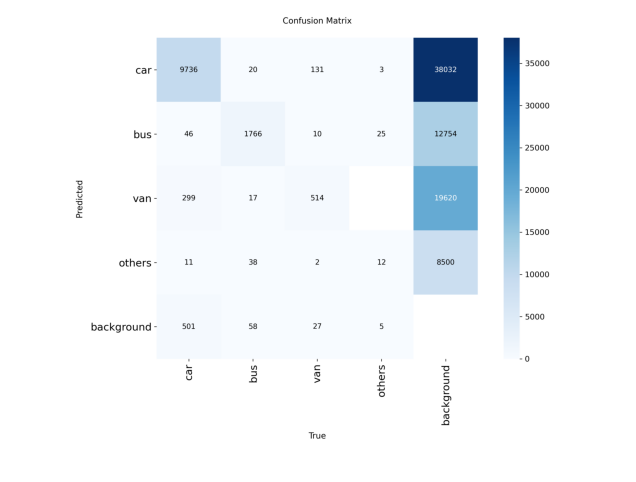

Saved /content/drive/.shortcut-targets-by-id/1bo0ITDfSqcaoFTjJXtJVrUDLpPS9E0SS/DATA255/outputs/yolov10_p2/test_eval/BoxPR_curve.png


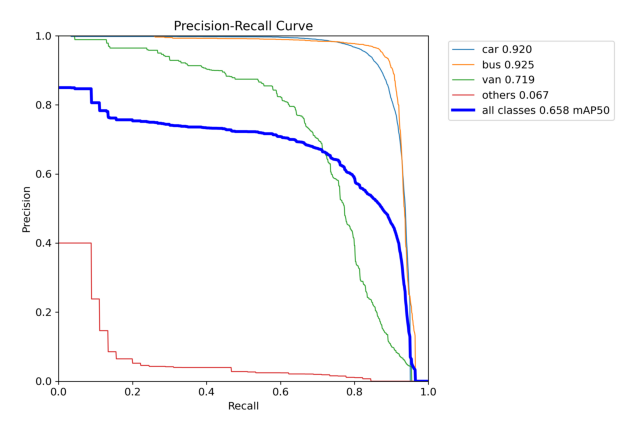

In [72]:
best_model = YOLO(BEST_PT)
test_results = best_model.val(data=RUNTIME_YAML, split='test', imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                              project=str(OUTPUT_DIR), name='test_eval', exist_ok=True, plots=True, verbose=False)

box = test_results.box
rows = [{'class': 'all', 'precision': box.mp, 'recall': box.mr, 'mAP50': box.map50, 'mAP50_95': box.map}]
for i, c in enumerate(box.ap_class_index):
    p, r, ap50, ap = box.class_result(i)
    rows.append({'class': CLASS_NAMES[c], 'precision': p, 'recall': r, 'mAP50': ap50, 'mAP50_95': ap})
ultralytics_test = pd.DataFrame(rows)
ultralytics_test.to_csv(OUTPUT_DIR / 'test_metrics_ultralytics.csv', index=False)
display(ultralytics_test.round(3))

save_dir = Path(test_results.save_dir)
for name in ['confusion_matrix.png', 'BoxPR_curve.png']:
    if (save_dir / name).exists():
        print('Saved', save_dir / name)
        plt.figure(figsize=(8, 6))
        plt.imshow(Image.open(save_dir / name))
        plt.axis('off')
        plt.show()

## 7. PER WEATHER EVALUATION

Report P2 mAP for each weather.

In [73]:
rows = []
for weather, yaml_file in WEATHER_YAMLS.items():
    r = best_model.val(data=yaml_file, split='test', imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                       project=str(OUTPUT_DIR), name=f'test_eval_{weather}', exist_ok=True, plots=False, verbose=False)
    rows.append({'weather': weather, 'images': int((test_df['weather'] == weather).sum()),
                 'mAP50': r.box.map50, 'mAP50_95': r.box.map})
weather_results = pd.DataFrame(rows)
weather_results.to_csv(OUTPUT_DIR / 'test_metrics_by_weather_ultralytics.csv', index=False)
display(weather_results.round(3))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv10s-p2 summary (fused): 118 layers, 7,272,800 parameters, 0 gradients, 27.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1881.9±522.6 MB/s, size: 60.1 KB)
val: Scanning /content/dataset_view/labels/test... 402 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 402/402 2.0Kit/s 0.2s
val: New cache created: /content/dataset_view/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 5.5it/s 4.7s
                   all        402       2258       0.82      0.798      0.849      0.534
Speed: 0.6ms preprocess, 7.5ms inference, 0.0ms loss, 1.0ms postprocess per image
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv10s-p2 summary (fused): 118 layers, 7,272,800 parameters, 0 gradients, 27.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 984.9±564.2 MB/s, size: 45.3 KB

,weather,images,mAP50,mAP50_95
0,cloudy,402,0.849,0.534
1,night,521,0.719,0.484
2,rainy,800,0.712,0.559
3,sunny,766,0.947,0.783


## 8. EXAMPLE PREDICTIONS

Display P2 predictions on one image per weather.

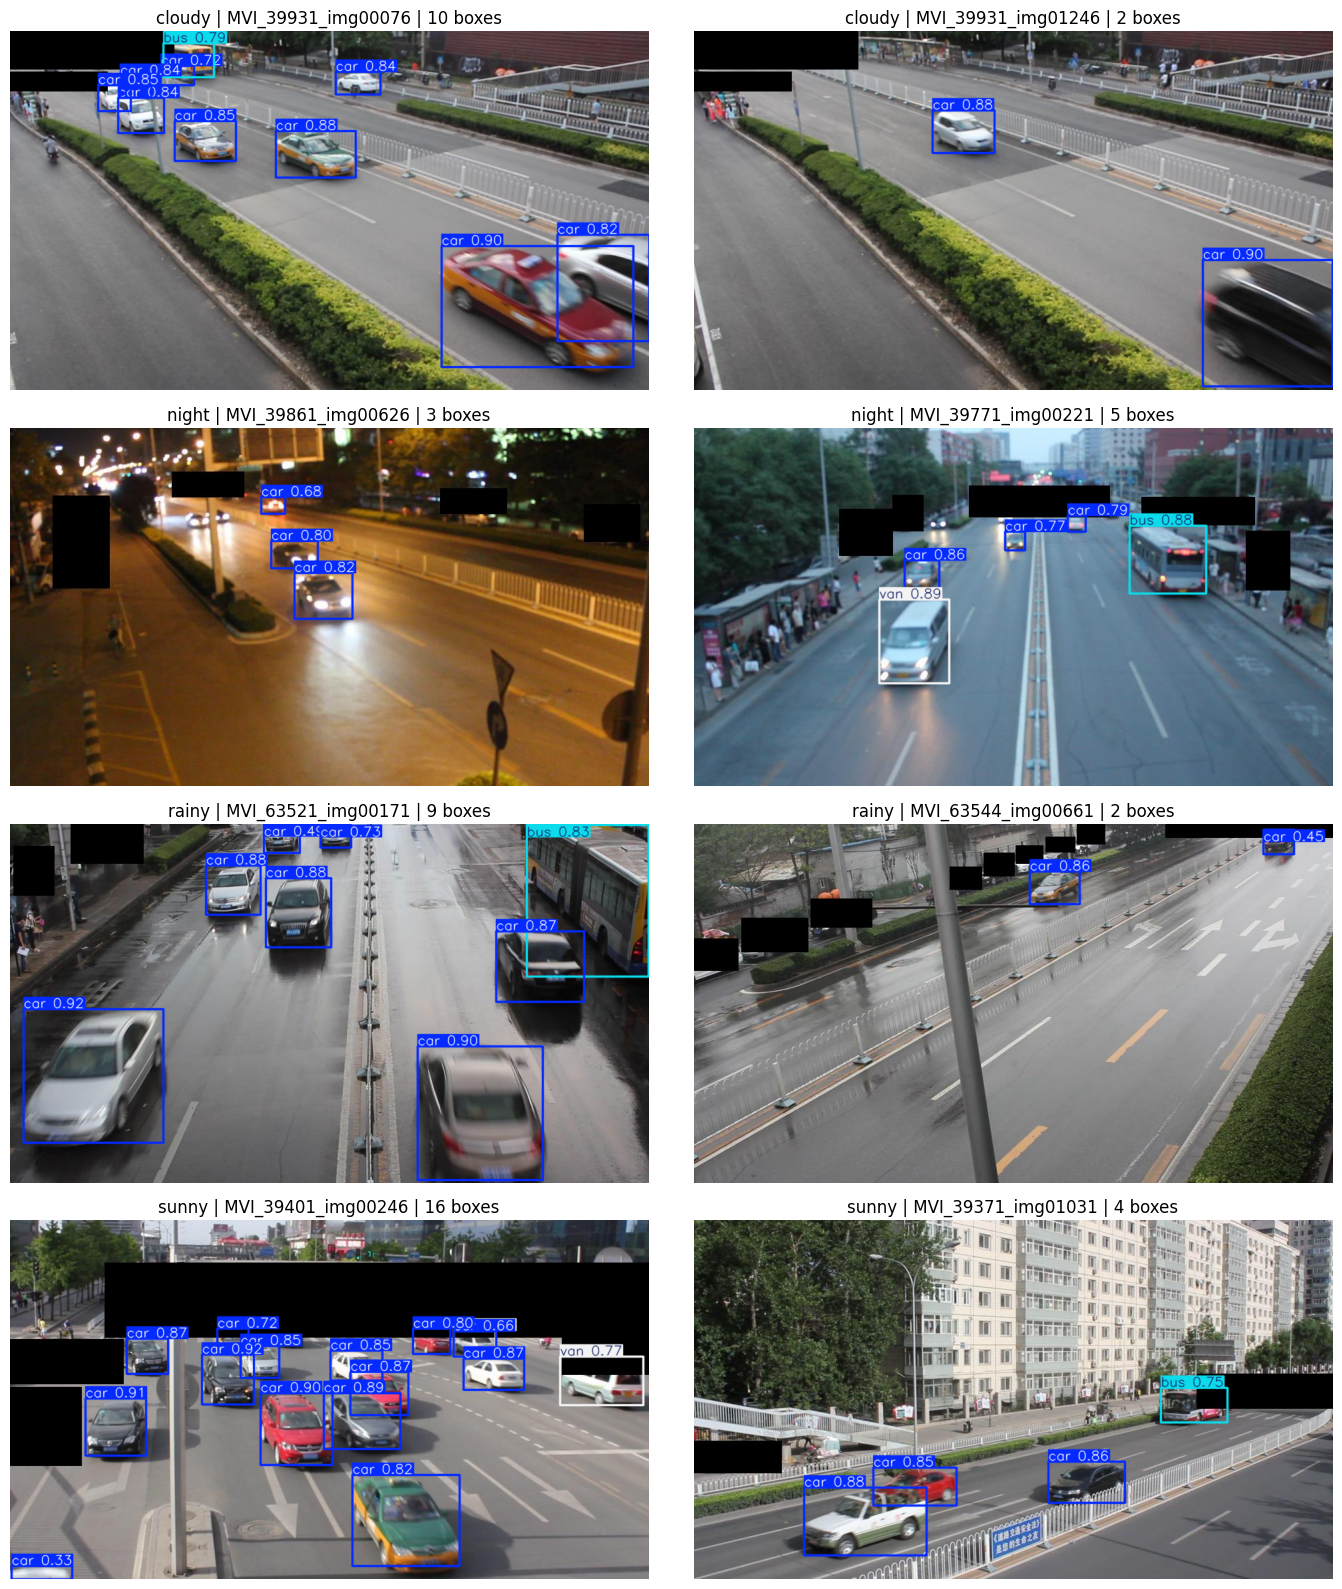

Saved examples to /content/drive/MyDrive/DATA255/outputs/yolov10_p2/examples


In [74]:
EXAMPLE_DIR = OUTPUT_DIR / 'examples'
EXAMPLE_DIR.mkdir(exist_ok=True)
examples = test_df.groupby('weather').sample(n=2, random_state=SEED)
fig, axes = plt.subplots(len(WEATHERS), 2, figsize=(14, 4 * len(WEATHERS)), squeeze=False)
for ax, row in zip(axes.flat, examples.itertuples()):
    result = best_model.predict(row.image_file, conf=COUNT_CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    result.save(filename=str(EXAMPLE_DIR / f'{row.weather}_{row.image}.jpg'))
    ax.imshow(result.plot()[:, :, ::-1])
    ax.set_title(f'{row.weather} | {row.image} | {len(result.boxes)} boxes')
    ax.axis('off')
plt.tight_layout()
plt.show()
print('Saved examples to', EXAMPLE_DIR)

## 9. DETECTIONS EXPORT

Save test detections for the comparison and fusion notebooks.

In [75]:
start = time.time()
p2_det = predict_detections(best_model, test_df, conf=EVAL_CONF)
print(f'P2 prediction: {time.time() - start:.0f}s')
p2_metrics = evaluate(test_gt, p2_det, test_df)
detections = (p2_det[p2_det['confidence'] >= COUNT_CONF]
              .merge(test_df[['image', 'sequence', 'frame', 'weather']], on='image', how='left'))
detections['class_name'] = detections['class_id'].map(dict(enumerate(CLASS_NAMES)))
detections = detections[['image', 'sequence', 'frame', 'weather', 'class_id', 'class_name', 'confidence'] + BOX_COLS]
detections.to_csv(OUTPUT_DIR / 'detections.csv', index=False)
print(f'{len(detections)} detections written to', OUTPUT_DIR / 'detections.csv')
display(detections.head())

P2 prediction: 35s
13419 detections written to /content/drive/MyDrive/DATA255/outputs/yolov10_p2/detections.csv


,image,sequence,frame,weather,class_id,class_name,confidence,x1,y1,x2,y2
0,MVI_39051_img00001,MVI_39051,1,sunny,0,car,0.792811,246.351059,452.314728,443.428772,539.835205
1,MVI_39051_img00001,MVI_39051,1,sunny,0,car,0.473424,866.039978,311.324982,918.848328,350.518555
2,MVI_39051_img00006,MVI_39051,6,sunny,0,car,0.775565,848.479797,318.927002,904.420166,357.726318
3,MVI_39051_img00006,MVI_39051,6,sunny,0,car,0.698084,158.848099,476.477142,359.459198,540.000000
4,MVI_39051_img00011,MVI_39051,11,sunny,0,car,0.827168,830.971619,321.327332,891.597839,362.616882


## 10. COUNTING

Compare predicted and true vehicle counts.

In [76]:
p2_counts = count_table(test_gt, p2_det, test_df)
base_counts = count_table(test_gt, base_det, test_df)
p2_counts.to_csv(OUTPUT_DIR / 'counts_per_image.csv', index=False)

p2_count_mae, base_count_mae = count_mae(p2_counts), count_mae(base_counts)
display(base_count_mae.merge(p2_count_mae, on=['group', 'metric'], suffixes=('_baseline', '_p2')).round(3))

,group,metric,value_baseline,value_p2
0,all,count_MAE,0.938,0.754
1,car,count_MAE,0.813,0.648
2,bus,count_MAE,0.174,0.159
3,van,count_MAE,0.198,0.237
4,others,count_MAE,0.033,0.101
5,weather:cloudy,count_MAE,1.060,0.905
6,weather:night,count_MAE,1.472,0.904
7,weather:rainy,count_MAE,0.955,0.695
8,weather:sunny,count_MAE,0.493,0.633


## 11. RESULTS TABLE

Compare baseline and P2 metrics and save the results.

In [77]:
base_all = pd.concat([base_metrics, base_count_mae])
p2_all = pd.concat([p2_metrics, p2_count_mae])
results = base_all.merge(p2_all, on=['group', 'metric'], suffixes=('_base', '_p2'))
results = results.rename(columns={'value_base': 'baseline', 'value_p2': 'p2'})
results['change'] = results['p2'] - results['baseline']
results.to_csv(OUTPUT_DIR / 'p2_vs_baseline_metrics.csv', index=False)
print('Saved', OUTPUT_DIR / 'p2_vs_baseline_metrics.csv', '| SMOKE_TEST =', SMOKE_TEST)
with pd.option_context('display.max_rows', 200):
    display(results.round(3))

Saved /content/drive/MyDrive/DATA255/outputs/yolov10_p2/p2_vs_baseline_metrics.csv | SMOKE_TEST = False


,group,metric,baseline,p2,change
0,all,mAP50,0.631,0.641,0.010
1,all,mAP50_95,0.469,0.479,0.010
2,all,precision,0.883,0.851,-0.032
3,all,recall,0.807,0.864,0.056
4,car,mAP50,0.863,0.898,0.035
5,car,mAP50_95,0.649,0.667,0.018
6,car,precision,0.910,0.904,-0.006
7,car,recall,0.815,0.865,0.050
8,bus,mAP50,0.889,0.914,0.025
9,bus,mAP50_95,0.672,0.667,-0.006


## 12. FUSION INPUTS AND EXTRA CHECKS

Save val/test detections and run the weather, count, and speed checks.

In [78]:
val_df = manifest[manifest['split'] == 'val']
if SMOKE_TEST:
    n = min(SMOKE_TEST_IMAGES_PER_WEATHER, val_df['weather'].value_counts().min())
    val_df = val_df.groupby('weather').sample(n=n, random_state=SEED)
val_df = val_df.reset_index(drop=True)
val_gt = load_ground_truth(val_df)

start = time.time()
val_det = predict_detections(best_model, val_df, conf=EVAL_CONF)
base_val_det = predict_detections(baseline_model, val_df, conf=EVAL_CONF)
print(f'Val prediction (both models): {time.time() - start:.0f}s')


def save_boxes(boxes, images_df, name):
    # Adds image info (fusion libraries need the image size) and writes one row per box.
    info = images_df[['image', 'sequence', 'frame', 'weather']].copy()
    sizes = [Image.open(f).size for f in images_df['image_file']]
    info['image_width'], info['image_height'] = [s[0] for s in sizes], [s[1] for s in sizes]
    out = boxes.merge(info, on='image', how='left')
    out['class_name'] = out['class_id'].map(dict(enumerate(CLASS_NAMES)))
    cols = ['image', 'sequence', 'frame', 'weather', 'image_width', 'image_height', 'class_id', 'class_name']
    out = out[cols + [c for c in ['confidence'] if c in out] + BOX_COLS]
    out.to_csv(OUTPUT_DIR / name, index=False)
    print(f'{len(out):>7} boxes in {len(images_df)} images ->', OUTPUT_DIR / name)


# P2 boxes down to confidence EVAL_CONF (fusion needs the low-confidence boxes too).
# Ground truth is not saved again: use the baseline's ground_truth_{val,test}.csv.
save_boxes(val_det, val_df, 'p2_detections_val.csv')
save_boxes(p2_det, test_df, 'p2_detections_test.csv')

Val prediction (both models): 65s
  86523 boxes in 2538 images -> /content/drive/MyDrive/DATA255/outputs/yolov10_p2/p2_detections_val.csv
  51744 boxes in 2489 images -> /content/drive/MyDrive/DATA255/outputs/yolov10_p2/p2_detections_test.csv


Report per weather scores with the vehicle class ignored.

In [79]:
rows = []
for weather, g in test_df.groupby('weather'):
    names = g['image'].tolist()
    gt_w = test_gt[test_gt['image'].isin(names)]
    for model_name, det, counts in [('baseline', base_det, base_counts), ('p2', p2_det, p2_counts)]:
        det_w = det[det['image'].isin(names)]
        ap_v = coco_ap(gt_w, det_w, names, agnostic=True)['vehicle']
        precision, recall = precision_recall(gt_w, det_w, agnostic=True)['vehicle']
        ap = coco_ap(gt_w, det_w, names)
        c = counts[counts['weather'] == weather]
        count_mae_w = (c['pred_total'] - c['gt_total']).abs().mean()
        rows.append({'weather': weather, 'model': model_name,
                     'vehicle_mAP50': ap_v[0], 'vehicle_mAP50_95': ap_v[1],
                     'vehicle_precision': precision, 'vehicle_recall': recall,
                     'mAP50_no_others': np.nanmean([ap[n][0] for n in CLASS_NAMES if n != 'others']),
                     'count_MAE': count_mae_w, 'vehicles_per_image': c['gt_total'].mean(),
                     'count_error_pct': 100 * count_mae_w / c['gt_total'].mean()})

weather_breakdown = pd.DataFrame(rows)
weather_breakdown.to_csv(OUTPUT_DIR / 'weather_breakdown.csv', index=False)
print('Saved', OUTPUT_DIR / 'weather_breakdown.csv')
display(weather_breakdown.round(3))

Saved /content/drive/MyDrive/DATA255/outputs/yolov10_p2/weather_breakdown.csv


,weather,model,vehicle_mAP50,vehicle_mAP50_95,vehicle_precision,vehicle_recall,mAP50_no_others,count_MAE,vehicles_per_image,count_error_pct
0,cloudy,baseline,0.835,0.534,0.812,0.793,0.746,1.060,5.617,18.866
1,cloudy,p2,0.878,0.538,0.804,0.861,0.838,0.905,5.617,16.120
2,night,baseline,0.692,0.474,0.926,0.609,0.613,1.472,4.117,35.758
3,night,p2,0.829,0.541,0.796,0.776,0.691,0.904,4.117,21.958
4,rainy,baseline,0.885,0.677,0.922,0.823,0.770,0.955,5.255,18.173
5,rainy,p2,0.905,0.684,0.922,0.864,0.811,0.695,5.255,13.225
6,sunny,baseline,0.977,0.787,0.930,0.951,0.936,0.493,6.023,8.192
7,sunny,p2,0.982,0.806,0.903,0.972,0.933,0.633,6.023,10.511


Choose count thresholds on val and report test count error.

In [80]:
THRESHOLDS = [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6]


def total_count_errors(gt, det, images_df, conf):
    # Absolute error of the total vehicle count in each image.
    predicted = det[det['confidence'] >= conf].groupby('image').size()
    true = gt.groupby('image').size()
    out = images_df[['image', 'weather']].copy()
    out['error'] = (out['image'].map(predicted).fillna(0) - out['image'].map(true).fillna(0)).abs()
    return out


runs = {('baseline', 'val'): (val_gt, base_val_det, val_df), ('baseline', 'test'): (test_gt, base_det, test_df),
        ('p2', 'val'): (val_gt, val_det, val_df), ('p2', 'test'): (test_gt, p2_det, test_df)}
rows = []
for (model_name, split), (gt, det, images_df) in runs.items():
    for conf in THRESHOLDS:
        errors = total_count_errors(gt, det, images_df, conf)
        rows.append({'model': model_name, 'split': split, 'conf': conf, 'group': 'all', 'count_MAE': errors['error'].mean()})
        rows += [{'model': model_name, 'split': split, 'conf': conf, 'group': f'weather:{w}', 'count_MAE': e['error'].mean()}
                 for w, e in errors.groupby('weather')]
count_by_threshold = pd.DataFrame(rows)
count_by_threshold.to_csv(OUTPUT_DIR / 'count_mae_by_threshold.csv', index=False)
print('Saved', OUTPUT_DIR / 'count_mae_by_threshold.csv')

overall = count_by_threshold[count_by_threshold['group'] == 'all']
display(overall.pivot_table(index='conf', columns=['model', 'split'], values='count_MAE').round(3))

# Pick each model's threshold on val, then report test at that threshold
best_conf = overall[overall['split'] == 'val'].loc[lambda d: d.groupby('model')['count_MAE'].idxmin()].set_index('model')['conf']
print('Threshold with lowest val count MAE:', best_conf.to_dict())
test_rows = count_by_threshold[(count_by_threshold['split'] == 'test')
                               & (count_by_threshold['conf'] == count_by_threshold['model'].map(best_conf))]
display(test_rows.pivot_table(index='group', columns='model', values='count_MAE').round(3))

Saved /content/drive/MyDrive/DATA255/outputs/yolov10_p2/count_mae_by_threshold.csv


model baseline            p2       
split     test    val   test    val
conf                               
0.10     1.072  1.382  1.214  1.416
0.15     0.953  1.308  0.970  1.324
0.20     0.931  1.348  0.832  1.303
0.25     0.938  1.459  0.754  1.337
0.30     0.944  1.611  0.719  1.393
0.35     0.976  1.796  0.701  1.492
0.40     1.014  2.000  0.708  1.604
0.50     1.135  2.455  0.798  1.944
0.60     1.313  2.866  1.017  2.576

Threshold with lowest val count MAE: {'baseline': 0.15, 'p2': 0.2}


model,baseline,p2
group,,
all,0.953,0.832
weather:cloudy,1.269,1.124
weather:night,1.234,0.990
weather:rainy,0.918,0.690
weather:sunny,0.632,0.719


Measure baseline and P2 speed on the same device.

In [81]:
def sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elif torch.backends.mps.is_available():
        torch.mps.synchronize()


def measure_fps(model, paths, batch):
    model.predict(paths[:batch], conf=COUNT_CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)   # warm-up
    sync()
    start = time.perf_counter()
    for i in range(0, len(paths), batch):
        model.predict(paths[i:i + batch], conf=COUNT_CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)
    sync()
    return len(paths) / (time.perf_counter() - start)


fps_paths = test_df.sample(n=min(300, len(test_df)), random_state=SEED)['image_file'].tolist()
for p in fps_paths:   # read every image once so neither model pays for cold disk reads
    Image.open(p).load()
device_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
speed = pd.DataFrame([{'model': name, 'device': device_name, 'batch': b, 'images': len(fps_paths),
                       'fps': measure_fps(m, fps_paths, b)}
                      for name, m in [('yolov10s_baseline', baseline_model), ('yolov10s_p2', best_model)] for b in [1, BATCH]])
speed['ms_per_image'] = 1000 / speed['fps']
speed.to_csv(OUTPUT_DIR / 'speed_fps.csv', index=False)
print('Saved', OUTPUT_DIR / 'speed_fps.csv')
display(speed.round(1))

Saved /content/drive/MyDrive/DATA255/outputs/yolov10_p2/speed_fps.csv


,model,device,batch,images,fps,ms_per_image
0,yolov10s_baseline,Tesla T4,1,300,65.5,15.3
1,yolov10s_baseline,Tesla T4,16,300,95.7,10.5
2,yolov10s_p2,Tesla T4,1,300,56.3,17.8
3,yolov10s_p2,Tesla T4,16,300,77.4,12.9


## 13. WHERE YOLO FAILS

Review P2 and baseline results by weather, size, occlusion, and missed vehicles.

In [ ]:
EXTRA_COLS = ['vehicle_size', 'occlusion_ratio', 'occlusion_level']
SIZE_LEVELS = ['small', 'medium', 'large']
OCCLUSION_LEVELS = ['none', 'partial', 'heavy']

# Use the first annotations.csv that has the extra columns (the dataset folder may hold an older copy)
candidates = [DATA_DIR / 'annotations.csv', ROOT / 'data' / 'processed' / 'annotations.csv',
              Path('/content/drive/MyDrive/DATA255/annotations.csv')]
ANN_FILE = next((p for p in candidates
                 if p.exists() and set(EXTRA_COLS) <= set(pd.read_csv(p, nrows=0).columns)), None)
assert ANN_FILE, f'No annotations.csv with {EXTRA_COLS}. Pull the repo, or on Colab copy data/processed/annotations.csv to MyDrive/DATA255/'
annotations = pd.read_csv(ANN_FILE)
annotations['image'] = annotations['image_path'].map(lambda p: Path(p).stem)
annotations['x1'], annotations['y1'] = annotations['left'], annotations['top']
annotations['x2'], annotations['y2'] = annotations['left'] + annotations['width'], annotations['top'] + annotations['height']
print('Extra labels from', ANN_FILE)


def attach_labels(gt, ann):
    # Copies size/occlusion onto each ground truth box by finding the same box in annotations.csv.
    gt = gt.copy()
    ann_by_image = dict(list(ann.groupby('image')))
    matched = {}
    for image, g in gt.groupby('image'):
        a = ann_by_image[image]
        ious = box_iou(g[BOX_COLS].to_numpy(), a[BOX_COLS].to_numpy())
        best = ious.argmax(axis=1)
        ok = ious[np.arange(len(g)), best] > 0.9          # the two files hold the same boxes, so IoU is ~1
        matched.update(dict(zip(g.index[ok], a.index[best[ok]])))
    assert len(matched) == len(gt), f'{len(gt) - len(matched)} label boxes not found in annotations.csv'
    rows = ann.loc[[matched[i] for i in gt.index], EXTRA_COLS]
    gt[EXTRA_COLS] = rows.to_numpy()
    gt['occlusion_ratio'] = gt['occlusion_ratio'].astype(float)
    return gt.merge(test_df[['image', 'weather']], on='image', how='left')


test_gt_labeled = attach_labels(test_gt, annotations)
display(pd.crosstab(test_gt_labeled['weather'], test_gt_labeled['vehicle_size'])[SIZE_LEVELS])
display(pd.crosstab(test_gt_labeled['weather'], test_gt_labeled['occlusion_level'])[OCCLUSION_LEVELS])

Extra labels from /content/drive/MyDrive/DATA255/annotations.csv


vehicle_size,small,medium,large
weather,,,
cloudy,553,1162,543
night,637,985,523
rainy,452,2103,1649
sunny,34,3160,1420


occlusion_level,none,partial,heavy
weather,,,
cloudy,1733,441,84
night,1800,276,69
rainy,3662,419,123
sunny,3667,816,131


Mark each true vehicle as found or missed.

In [83]:
def match_boxes(gt, det, conf=COUNT_CONF):
    # Returns (found: True per ground-truth box that was detected, correct: True per detection that hit a vehicle).
    det = det[det['confidence'] >= conf].sort_values('confidence', ascending=False)
    found = pd.Series(False, index=gt.index)
    correct = pd.Series(False, index=det.index)
    det_by_image = dict(list(det.groupby('image')))
    for image, g in gt.groupby('image'):
        d = det_by_image.get(image)
        if d is None:
            continue
        ious = box_iou(d[BOX_COLS].to_numpy(), g[BOX_COLS].to_numpy())
        used = np.zeros(len(g), dtype=bool)
        for i, idx in enumerate(d.index):                  # highest confidence first
            candidates = np.where(~used & (ious[i] >= IOU_MATCH))[0]
            if len(candidates):
                used[candidates[np.argmax(ious[i, candidates])]] = True
                correct[idx] = True
        found[g.index[used]] = True
    return found, correct


MODELS = {'baseline': (base_det, base_counts), 'p2': (p2_det, p2_counts)}
matches = {name: match_boxes(test_gt_labeled, det) for name, (det, _) in MODELS.items()}
for name, (found, _) in matches.items():
    test_gt_labeled[f'found_{name}'] = found
    print(f'{name}: overall vehicle recall {found.mean():.3f}')

baseline: overall vehicle recall 0.828
p2: overall vehicle recall 0.887


Score results for day, low-light, and weather conditions.

In [84]:
LOW_LIGHT, RAIN = 'night', 'rainy'
assert {LOW_LIGHT, RAIN} <= set(WEATHERS), WEATHERS
CONDITION_GROUPS = {
    'all': WEATHERS,
    'day': [w for w in WEATHERS if w != LOW_LIGHT],
    'low_light': [LOW_LIGHT],
    'rain': [RAIN],
    'dry_day': [w for w in WEATHERS if w not in (LOW_LIGHT, RAIN)],
    **{f'weather:{w}': [w] for w in WEATHERS},
}

rows = []
for group, weathers in CONDITION_GROUPS.items():
    names = test_df.loc[test_df['weather'].isin(weathers), 'image'].tolist()
    gt_g = test_gt[test_gt['image'].isin(names)]
    for model_name, (det, counts) in MODELS.items():
        det_g = det[det['image'].isin(names)]
        ap50, ap50_95 = coco_ap(gt_g, det_g, names, agnostic=True)['vehicle']
        precision, recall = precision_recall(gt_g, det_g, agnostic=True)['vehicle']
        c = counts[counts['image'].isin(names)]
        mae = (c['pred_total'] - c['gt_total']).abs().mean()
        rows.append({'group': group, 'model': model_name, 'images': len(names), 'vehicles': len(gt_g),
                     'mAP50': ap50, 'mAP50_95': ap50_95, 'precision': precision, 'recall': recall,
                     'F1': 2 * precision * recall / (precision + recall),
                     'count_MAE': mae, 'count_error_pct': 100 * mae / c['gt_total'].mean()})

condition_table = pd.DataFrame(rows)
condition_table.to_csv(OUTPUT_DIR / 'condition_breakdown.csv', index=False)
print('Saved', OUTPUT_DIR / 'condition_breakdown.csv')
display(condition_table.set_index(['group', 'model']).round(3))

Saved /content/drive/MyDrive/DATA255/outputs/yolov10_p2/condition_breakdown.csv


images  vehicles  mAP50  mAP50_95  precision  recall  \
group          model                                                            
all            baseline    2489     13221  0.879     0.657      0.906   0.828   
               p2          2489     13221  0.916     0.677      0.874   0.887   
day            baseline    1968     11076  0.914     0.692      0.903   0.870   
               p2          1968     11076  0.931     0.703      0.888   0.908   
low_light      baseline     521      2145  0.692     0.474      0.926   0.609   
               p2           521      2145  0.829     0.541      0.796   0.776   
rain           baseline     800      4204  0.885     0.677      0.922   0.823   
               p2           800      4204  0.905     0.684      0.922   0.864   
dry_day        baseline    1168      6872  0.934     0.703      0.893   0.899   
               p2          1168      6872  0.950     0.715      0.870   0.936   
weather:cloudy baseline     402      2258  0.835     0.534      0.812   0.793   
               p2           402      2258  0.878     0.538      0.804   0.861   
weather:night  baseline     521      2145  0.692     0.474      0.926   0.609   
               p2           521      2145  0.829     0.541      0.796   0.776   
weather:rainy  baseline     800      4204  0.885     0.677      0.922   0.823   
               p2           800      4204  0.905     0.684      0.922   0.864   
weather:sunny  baseline     766      4614  0.977     0.787      0.930   0.951   
               p2           766      4614  0.982     0.806      0.903   0.972   

                            F1  count_MAE  count_error_pct  
group          model                                        
all            baseline  0.865      0.938           17.661  
               p2        0.880      0.754           14.190  
day            baseline  0.886      0.797           14.157  
               p2        0.898      0.714           12.685  
low_light      baseline  0.735      1.472           35.758  
               p2        0.786      0.904           21.958  
rain           baseline  0.870      0.955           18.173  
               p2        0.892      0.695           13.225  
dry_day        baseline  0.896      0.688           11.700  
               p2        0.902      0.727           12.354  
weather:cloudy baseline  0.802      1.060           18.866  
               p2        0.831      0.905           16.120  
weather:night  baseline  0.735      1.472           35.758  
               p2        0.786      0.904           21.958  
weather:rainy  baseline  0.870      0.955           18.173  
               p2        0.892      0.695           13.225  
weather:sunny  baseline  0.941      0.493            8.192  
               p2        0.936      0.633           10.511

Compare average brightness across weather conditions.

In [85]:
def brightness(path):
    return np.asarray(Image.open(path).convert('L').resize((160, 90))).mean()

test_df['brightness'] = [brightness(p) for p in test_df['image_file']]
display(test_df.groupby('weather')['brightness'].describe()[['min', '25%', '50%', '75%', 'max']].round(1))
darkest_day = test_df.loc[test_df['weather'] != LOW_LIGHT, 'brightness'].min()
night_b = test_df.loc[test_df['weather'] == LOW_LIGHT, 'brightness']
print(f'Night images darker than every daytime image: {(night_b < darkest_day).mean():.0%}')

,min,25%,50%,75%,max
weather,,,,,
cloudy,106.3,112.2,113.7,114.9,125.3
night,53.6,73.8,79.8,86.1,102.5
rainy,97.3,110.6,115.5,118.1,131.1
sunny,83.0,94.6,109.7,119.7,124.6


Night images darker than every daytime image: 65%


Plot recall by vehicle size and occlusion.

In [86]:
rows = []
for group, weathers in CONDITION_GROUPS.items():
    g = test_gt_labeled[test_gt_labeled['weather'].isin(weathers)]
    for attribute, levels in [('vehicle_size', SIZE_LEVELS), ('occlusion_level', OCCLUSION_LEVELS)]:
        for level in levels:
            x = g[g[attribute] == level]
            rows.append({'group': group, 'attribute': attribute, 'level': level, 'vehicles': len(x),
                         **{f'recall_{m}': x[f'found_{m}'].mean() if len(x) else np.nan for m in MODELS}})
size_occlusion = pd.DataFrame(rows)
size_occlusion.to_csv(OUTPUT_DIR / 'recall_by_size_occlusion.csv', index=False)
print('Saved', OUTPUT_DIR / 'recall_by_size_occlusion.csv')

print('P2 recall (rows = size / occlusion, columns = condition):')
display(size_occlusion.pivot_table(index=['attribute', 'level'], columns='group', values='recall_p2', sort=False)
        [list(CONDITION_GROUPS)].round(3))
print('Baseline vs. P2, all test images:')
display(size_occlusion[size_occlusion['group'] == 'all'].drop(columns='group').round(3))

Saved /content/drive/MyDrive/DATA255/outputs/yolov10_p2/recall_by_size_occlusion.csv
P2 recall (rows = size / occlusion, columns = condition):


group                      all    day  low_light   rain  dry_day  \
attribute       level                                              
vehicle_size    small    0.421  0.436      0.396  0.115    0.683   
                medium   0.936  0.940      0.910  0.925    0.948   
                large    0.988  0.988      0.989  0.991    0.985   
occlusion_level none     0.887  0.904      0.799  0.850    0.941   
                partial  0.899  0.942      0.638  0.976    0.931   
                heavy    0.835  0.858      0.725  0.878    0.847   

group                    weather:cloudy  weather:night  weather:rainy  \
attribute       level                                                   
vehicle_size    small             0.687          0.396          0.115   
                medium            0.885          0.910          0.925   
                large             0.987          0.989          0.991   
occlusion_level none              0.866          0.799          0.850   
                partial           0.868          0.638          0.976   
                heavy             0.726          0.725          0.878   

group                    weather:sunny  
attribute       level                   
vehicle_size    small            0.618  
                medium           0.971  
                large            0.985  
occlusion_level none             0.976  
                partial          0.964  
                heavy            0.924

Baseline vs. P2, all test images:


,attribute,level,vehicles,recall_baseline,recall_p2
0,vehicle_size,small,1676,0.269,0.421
1,vehicle_size,medium,7410,0.872,0.936
2,vehicle_size,large,4135,0.976,0.988
3,occlusion_level,none,10862,0.824,0.887
4,occlusion_level,partial,1952,0.863,0.899
5,occlusion_level,heavy,407,0.769,0.835


Compare count error for images with occluded vehicles.

In [87]:
occluded_share = (test_gt_labeled.assign(occluded=test_gt_labeled['occlusion_level'] != 'none')
                  .groupby('image')['occluded'].mean())
OCC_BINS = [0, 0.25, 0.5, 1.0001]
OCC_NAMES = ['< 25% occluded', '25-50% occluded', '>= 50% occluded']

rows = []
for model_name, (_, counts) in MODELS.items():
    c = counts.copy()
    c['occluded_share'] = c['image'].map(occluded_share)
    c['occlusion_group'] = pd.cut(c['occluded_share'], OCC_BINS, labels=OCC_NAMES, right=False)
    c['abs_error'] = (c['pred_total'] - c['gt_total']).abs()
    for (group, weathers) in [('all', WEATHERS), ('day', CONDITION_GROUPS['day']), ('low_light', [LOW_LIGHT])]:
        for occ, x in c[c['weather'].isin(weathers)].groupby('occlusion_group', observed=False):
            rows.append({'group': group, 'occlusion_group': occ, 'model': model_name, 'images': len(x),
                         'count_MAE': x['abs_error'].mean(),
                         'count_error_pct': 100 * x['abs_error'].mean() / x['gt_total'].mean() if len(x) else np.nan})
count_by_occlusion = pd.DataFrame(rows)
count_by_occlusion.to_csv(OUTPUT_DIR / 'count_by_occlusion.csv', index=False)
print('Saved', OUTPUT_DIR / 'count_by_occlusion.csv')
display(count_by_occlusion.pivot_table(index=['group', 'occlusion_group'], columns='model',
                                       values=['images', 'count_MAE', 'count_error_pct'], observed=False, sort=False).round(2))

Saved /content/drive/MyDrive/DATA255/outputs/yolov10_p2/count_by_occlusion.csv


images         count_MAE       count_error_pct  \
model                     baseline      p2  baseline    p2        baseline   
group     occlusion_group                                                    
all       < 25% occluded    1742.0  1742.0      0.94  0.71           18.11   
          25-50% occluded    471.0   471.0      1.09  0.98           15.18   
          >= 50% occluded    275.0   275.0      0.68  0.64           22.82   
day       < 25% occluded    1390.0  1390.0      0.82  0.70           15.22   
          25-50% occluded    386.0   386.0      0.90  0.92           11.57   
          >= 50% occluded    191.0   191.0      0.40  0.41           13.75   
low_light < 25% occluded     352.0   352.0      1.39  0.76           32.50   
          25-50% occluded     85.0    85.0      1.94  1.26           44.59   
          >= 50% occluded     84.0    84.0      1.32  1.14           42.05   

                                  
model                         p2  
group     occlusion_group         
all       < 25% occluded   13.76  
          25-50% occluded  13.61  
          >= 50% occluded  21.24  
day       < 25% occluded   12.96  
          25-50% occluded  11.73  
          >= 50% occluded  14.11  
low_light < 25% occluded   17.74  
          25-50% occluded  28.92  
          >= 50% occluded  36.36

Display examples of missed detections and false positives.

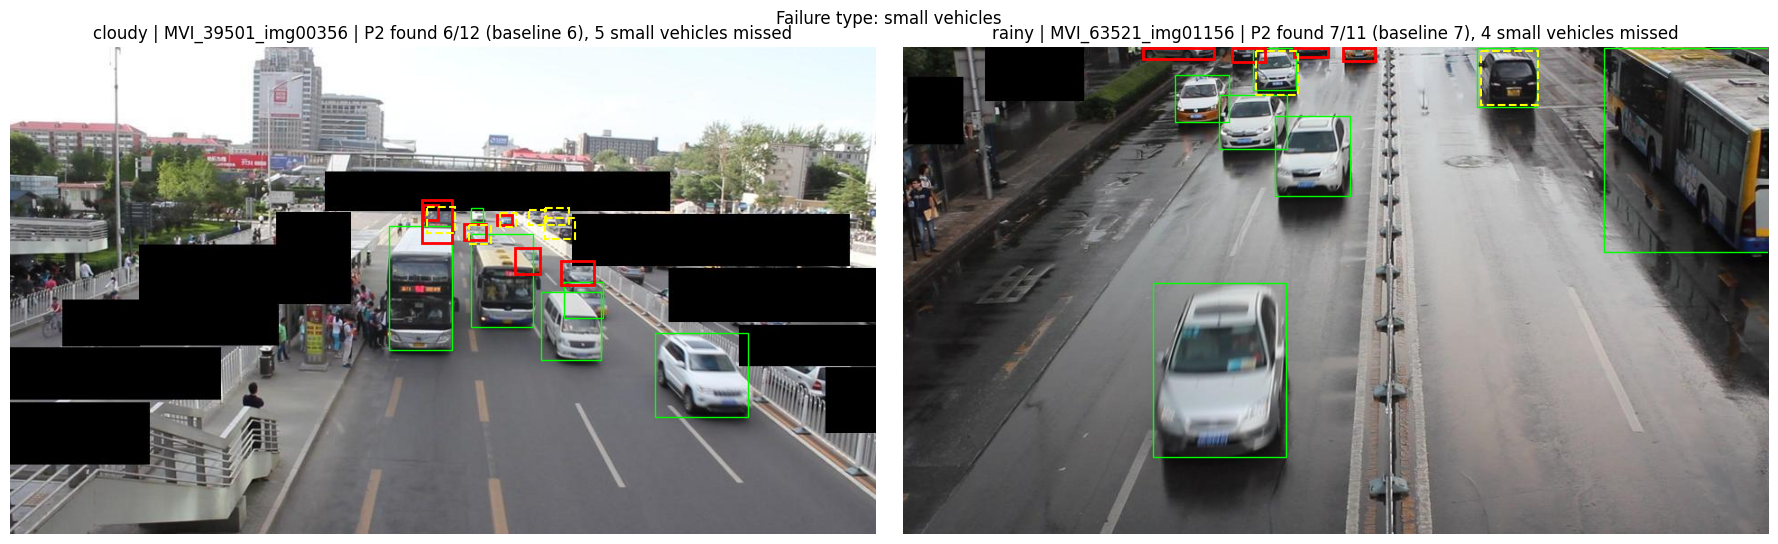

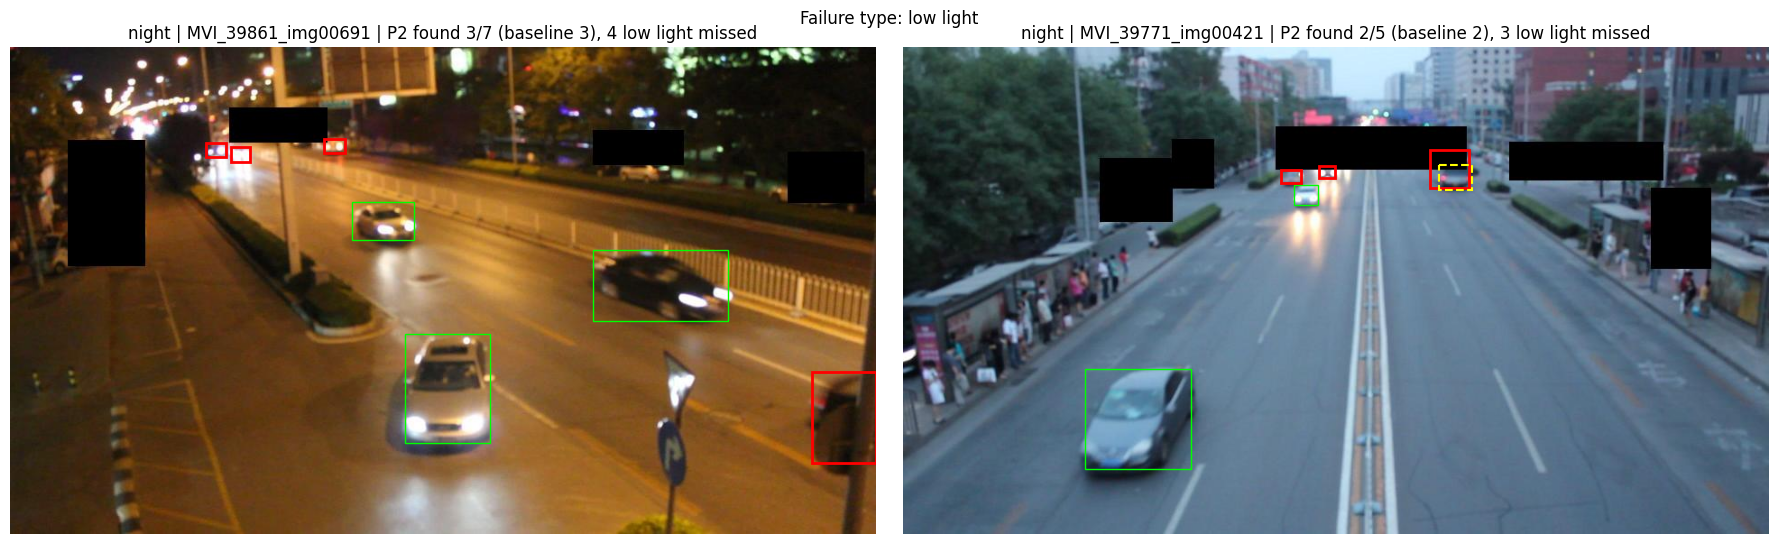

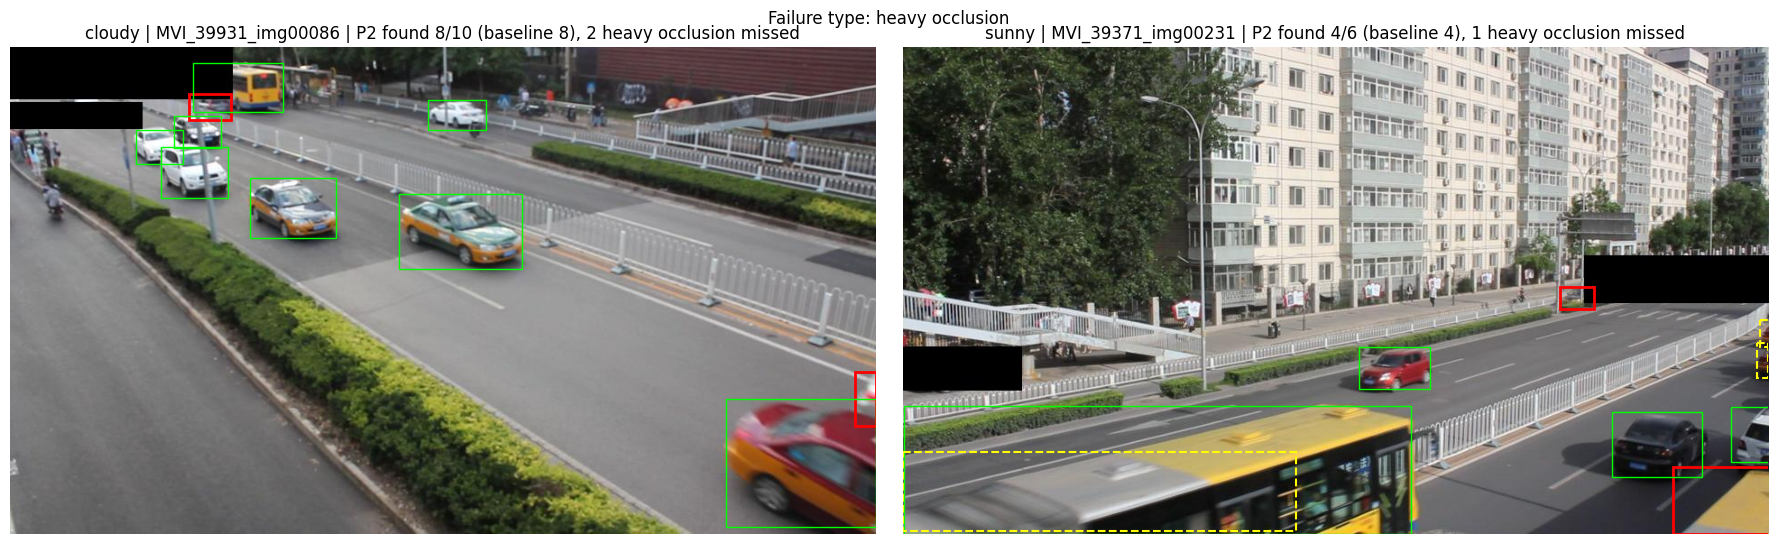

Saved failure examples to /content/drive/MyDrive/DATA255/outputs/yolov10_p2/failure_examples


In [88]:
from matplotlib.patches import Rectangle

FAIL_DIR = OUTPUT_DIR / 'failure_examples'
FAIL_DIR.mkdir(exist_ok=True)
p2_found, p2_correct = matches['p2']
p2_shown = p2_det[p2_det['confidence'] >= COUNT_CONF].assign(correct=p2_correct)
missed = test_gt_labeled[~test_gt_labeled['found_p2']]
FAILURE_TYPES = {
    'small_vehicles': missed[missed['vehicle_size'] == 'small'],
    'low_light': missed[missed['weather'] == LOW_LIGHT],
    'heavy_occlusion': missed[missed['occlusion_level'] == 'heavy'],
}


def worst_images(misses, n=2):
    # Images with the most misses, at most one per video.
    per_image = misses.groupby('image').size().rename('misses').reset_index()
    per_image = per_image.merge(test_df[['image', 'sequence']], on='image').sort_values('misses', ascending=False)
    return per_image.drop_duplicates('sequence').head(n)


for failure, misses in FAILURE_TYPES.items():
    picks = worst_images(misses)
    fig, axes = plt.subplots(1, len(picks), figsize=(9 * len(picks), 5.5), squeeze=False)
    for ax, row in zip(axes.flat, picks.itertuples()):
        info = test_df.set_index('image').loc[row.image]
        ax.imshow(Image.open(info['image_file']))
        g = test_gt_labeled[test_gt_labeled['image'] == row.image]
        for r in g.itertuples():
            ok, recovered = r.found_p2, r.found_p2 and not r.found_baseline
            ax.add_patch(Rectangle((r.x1, r.y1), r.x2 - r.x1, r.y2 - r.y1, fill=False,
                                   edgecolor='cyan' if recovered else ('lime' if ok else 'red'),
                                   linewidth=2 if recovered or not ok else 1))
        for r in p2_shown[(p2_shown['image'] == row.image) & ~p2_shown['correct']].itertuples():
            ax.add_patch(Rectangle((r.x1, r.y1), r.x2 - r.x1, r.y2 - r.y1, fill=False,
                                   edgecolor='yellow', linewidth=1.5, linestyle='--'))
        ax.set_title(f'{info["weather"]} | {row.image} | P2 found {g["found_p2"].sum()}/{len(g)} '
                     f'(baseline {g["found_baseline"].sum()}), {row.misses} {failure.replace("_", " ")} missed')
        ax.axis('off')
    fig.suptitle(f'Failure type: {failure.replace("_", " ")}')
    plt.tight_layout()
    fig.savefig(FAIL_DIR / f'{failure}.png', dpi=110, bbox_inches='tight')
    plt.show()
print('Saved failure examples to', FAIL_DIR)

Save the final settings and model summary.

In [ ]:
import ultralytics

history = pd.read_csv(RUN_DIR / 'results.csv')
history.columns = history.columns.str.strip()
# best.pt keeps the val scores of the epoch it was saved at; find that epoch in the training history
best_val = torch.load(BEST_PT, map_location='cpu', weights_only=False)['train_metrics']
best_row = history.loc[(history['metrics/mAP50-95(B)'] - best_val['metrics/mAP50-95(B)']).abs().idxmin()]
cond = condition_table.set_index(['group', 'model'])
fps = speed.set_index(['model', 'batch'])['fps']
labeled = test_gt_labeled


def key_results(m):
    return {
        'mAP50_4_classes': float(results.set_index(['group', 'metric']).loc[('all', 'mAP50'), m]),
        **{f'{g}_{k}': float(cond.loc[(g, m), k])
           for g in ['all', 'day', 'low_light', 'rain', 'dry_day'] for k in ['mAP50', 'recall', 'F1', 'count_MAE']},
        'small_vehicle_recall': float(labeled.loc[labeled['vehicle_size'] == 'small', f'found_{m}'].mean()),
        'small_vehicle_recall_low_light': float(labeled.loc[(labeled['vehicle_size'] == 'small')
                                                            & (labeled['weather'] == LOW_LIGHT), f'found_{m}'].mean()),
        'partial_occlusion_recall': float(labeled.loc[labeled['occlusion_level'] == 'partial', f'found_{m}'].mean()),
        'heavy_occlusion_recall': float(labeled.loc[labeled['occlusion_level'] == 'heavy', f'found_{m}'].mean()),
    }


def size_info_trained(m):   # 4 class models, as actually trained
    return {'params_M': sum(p.numel() for p in m.model.parameters()) / 1e6, 'GFLOPs': get_flops(m.model, IMGSZ)}


summary = {
    'model': MODEL, 'pretrained': PRETRAINED, 'weights': str(BEST_PT.relative_to(OUTPUT_DIR)),
    'best_epoch': int(best_row['epoch']), 'epochs_trained': len(history),
    'best_val_mAP50': float(best_row['metrics/mAP50(B)']), 'best_val_mAP50_95': float(best_row['metrics/mAP50-95(B)']),
    'architecture': {**ARCH_INFO, 'baseline_trained': size_info_trained(baseline_model), 'p2_trained': size_info_trained(best_model)},
    'settings': {'max_epochs': EPOCHS, 'patience': PATIENCE, 'imgsz': IMGSZ, 'batch': BATCH, 'seed': SEED,
                 'eval_conf': EVAL_CONF, 'count_conf': COUNT_CONF, 'iou_match': IOU_MATCH,
                 'augmentation': 'Ultralytics defaults', 'ultralytics': ultralytics.__version__},
    'test': {'baseline': key_results('baseline'), 'p2': key_results('p2')},
    'speed': {'device': speed['device'].iloc[0],
              **{f'{n}_fps_batch_{b}': float(fps[(f'yolov10s_{n}', b)]) for n in ['baseline', 'p2'] for b in [1, BATCH]}},
}
(OUTPUT_DIR / 'final_model_summary.json').write_text(json.dumps(summary, indent=2))
print('Saved', OUTPUT_DIR / 'final_model_summary.json')
print(json.dumps(summary, indent=2))

Saved /content/drive/MyDrive/DATA255/outputs/yolov10_p2/final_model_summary.json
{
  "model": "/content/drive/MyDrive/DATA255/yolov10s-p2.yaml",
  "pretrained": "yolov10s.pt",
  "weights": "finetune/weights/best.pt",
  "best_epoch": 12,
  "epochs_trained": 22,
  "best_val_mAP50": 0.87094,
  "best_val_mAP50_95": 0.64476,
  "architecture": {
    "strides": [
      4,
      8,
      16,
      32
    ],
    "transferred_tensors": 378,
    "total_tensors": 723,
    "layers_starting_from_scratch": [
      25,
      26
    ],
    "baseline_nc80": {
      "params_M": 8.128272,
      "GFLOPs": 25.2277248
    },
    "p2_nc80": {
      "params_M": 8.188336,
      "GFLOPs": 36.4979968
    },
    "baseline_trained": {
      "params_M": 8.069448,
      "GFLOPs": 24.900864
    },
    "p2_trained": {
      "params_M": 8.139088,
      "GFLOPs": 35.6711168
    }
  },
  "settings": {
    "max_epochs": 50,
    "patience": 10,
    "imgsz": 640,
    "batch": 16,
    "seed": 0,
    "eval_conf": 0.001,
    "c